<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>
*Copyright by Pierian Data Inc.*

# Template Matching

### Full Image

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
full = cv2.imread('data/sammy.jpg')
full = cv2.cvtColor(full, cv2.COLOR_BGR2RGB)

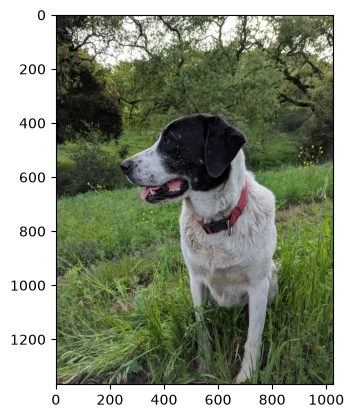

In [5]:
plt.imshow(full)

### Template Image

A subset of the image. Note how its actually the exact image. Later on we'll discuss more advanced methods for general matching, such as facial recognition.

In [15]:
face = cv2.imread('data/sammy_face.jpg')
face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)

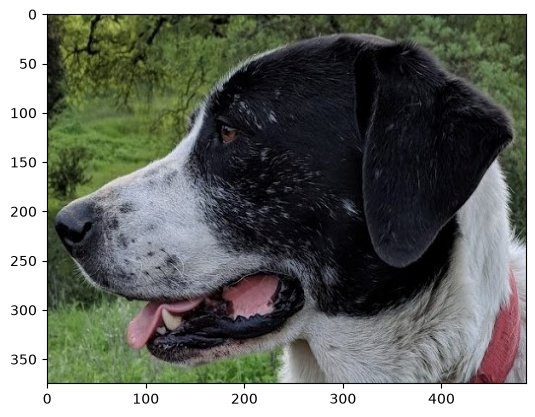

In [16]:
plt.imshow(face)

# Template Matching Methods

Make sure to watch the video for an explanation of the different methods!

-------

**Quick Note on **eval()** function in case you haven't seen it before!**

In [11]:
lst = [1,2,3,4,5,6,7,8,9]
sum(lst)

45

In [7]:
mystring = 'sum'

In [8]:
eval(mystring)

<function sum(iterable, /, start=0)>

In [9]:
myfunc = eval(mystring)

In [12]:
myfunc(lst)

45

`eval()` evaluates a string as a Python expression.

> **Important:** `eval()` can execute arbitrary Python expressions, so avoid using it with untrusted input. A dictionary mapping names to constants is safer.

--------

In [17]:
face.shape

(375, 486, 3)

In [18]:
height, width,channels = face.shape

In [19]:
height, width, channels

(375, 486, 3)

----------

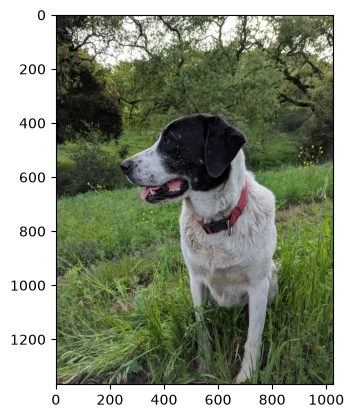

In [20]:
# Full image
full = cv2.imread('data/sammy.jpg')
full = cv2.cvtColor(full, cv2.COLOR_BGR2RGB)
plt.imshow(full)

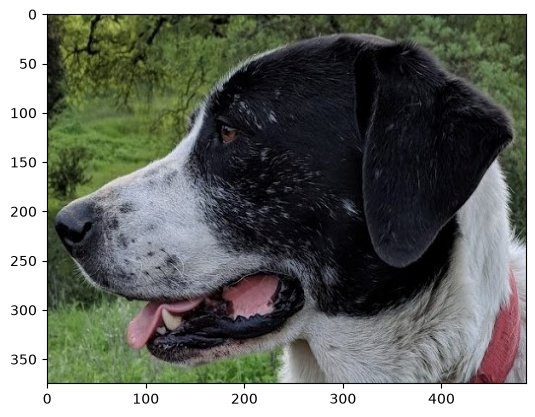

In [21]:
# Template to match (face only)
face = cv2.imread('data/sammy_face.jpg')
face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
plt.imshow(face)

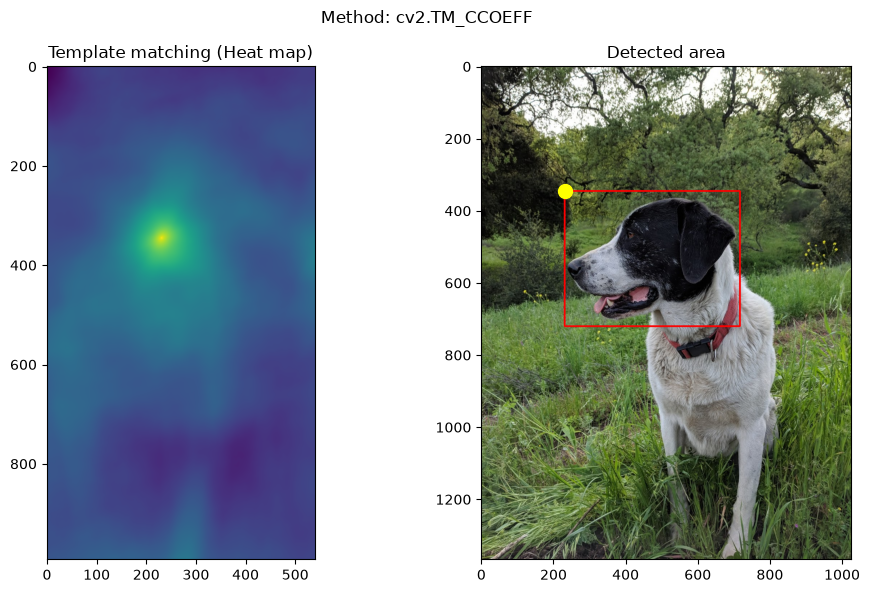

In [38]:
method = 'cv2.TM_CCOEFF'
full_copy = full.copy()
method = eval(method) 

# Apply template matching with method
res= cv2.matchTemplate(image = full_copy, # the larger image being searched
                       templ = face,      # the smaller image wanted to locate
                       method = method)   # the matching algorithm

# OpenCV function that finds the minimum and maximum values in a matrix 
# and the locations where those values occur.
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res) # (-735640896.0, 1755028480.0, (0, 10), (231, 345))

top_left = max_loc # (231, 345) --> (x, y)
x, y = top_left

# width = 486 & height = 375
bottom_right = (top_left[0]+width, top_left[1]+height) # (717, 720) --> (x, y)

# Draw rectangle
cv2.rectangle(img = full_copy, 
              pt1 = top_left, 
              pt2 = bottom_right, 
              color = 255, 
              thickness = 3)


figure, ax = plt.subplots(1, 2, figsize=(10, 6))
ax[0].imshow(res)
ax[0].set_title("Template matching (Heat map)")

ax[1].imshow(full_copy)
ax[1].set_title("Detected area")

# Plot the max_loc point
plt.scatter(top_left[0], top_left[1], color='yellow', s=100, marker='o',
            label=f'max_loc = ({x}, {y})')

plt.suptitle("Method: cv2.TM_CCOEFF")
plt.tight_layout()
plt.show()

In [14]:
# The Full Image to Search
full = cv2.imread('../DATA/sammy.jpg')
full = cv2.cvtColor(full, cv2.COLOR_BGR2RGB)


# The Template to Match
face= cv2.imread('../DATA/sammy_face.jpg')
face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)


# All the 6 methods for comparison in a list
# Note how we are using strings, later on we'll use the eval() function to convert to function
methods = ['cv2.TM_CCOEFF', 'cv2.TM_CCOEFF_NORMED', 'cv2.TM_CCORR','cv2.TM_CCORR_NORMED', 'cv2.TM_SQDIFF', 'cv2.TM_SQDIFF_NORMED']

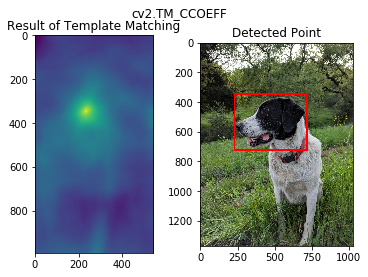

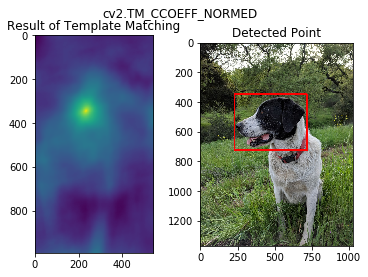

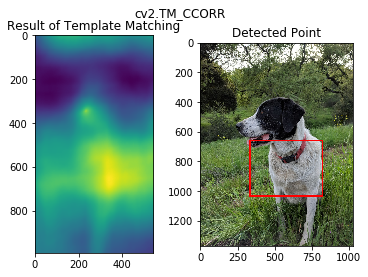

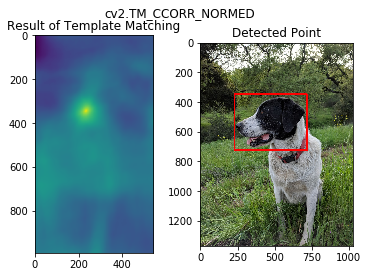

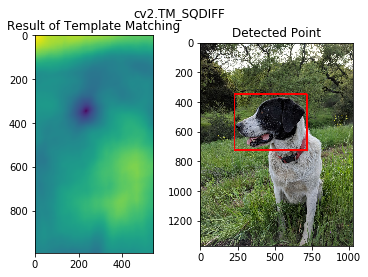

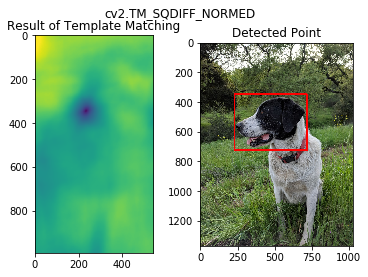

In [15]:
for m in methods:
    
    # Create a copy of the image
    full_copy = full.copy()
    
    # Get the actual function instead of the string
    method = eval(m)

    # Apply template Matching with the method
    res = cv2.matchTemplate(full_copy,face,method)
    
    # Grab the Max and Min values, plus their locations
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
    
    # Set up drawing of Rectangle
    
    # If the method is TM_SQDIFF or TM_SQDIFF_NORMED, take minimum
    # Notice the coloring on the last 2 left hand side images.
    if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
        top_left = min_loc    
    else:
        top_left = max_loc
        
    # Assign the Bottom Right of the rectangle
    bottom_right = (top_left[0] + width, top_left[1] + height)

    # Draw the Red Rectangle
    cv2.rectangle(full_copy,top_left, bottom_right, 255, 10)

    # Plot the Images
    plt.subplot(121)
    plt.imshow(res)
    plt.title('Result of Template Matching')
    
    plt.subplot(122)
    plt.imshow(full_copy)
    plt.title('Detected Point')
    plt.suptitle(m)
    
    
    plt.show()
    print('\n')
    print('\n')
    